# Tugas Proyek AI5103 Fundamental AI dan Sains Data

Judul: Comparative Analysis of Genetic Algorithm and Particle Swarm Optimization for Optimal Power Flow on IEEE 30-Bus System


Anggota Kelompok:
1) Berwyn Izzut Taghyir | 28426003
2) Varraz Hazzandra A | 28426011

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
pd.set_option("display.width", 120)

## Loading Dataset

Studi kasus: IEEE-30 Bus Network, minimisasi biaya bahan bakar kuadratik.

Source: https://github.com/ITI/models/blob/master/electric-grid/physical/reference/ieee-30bus/models/ieee-30-bus.m

Menetapkan basis daya sistem sebesar 100 MVA.

In [ ]:
BASE_MVA = 100.0

Memasukkan tipe bus dan beban aktif serta reaktif di setiap bus.

In [ ]:
bus_list = [
    (1,3,0.0,0.0),    (2,2,21.7,12.7),  (3,1,2.4,1.2),    (4,1,7.6,1.6),
    (5,2,94.2,19.0),  (6,1,0.0,0.0),    (7,1,22.8,10.9),  (8,2,30.0,30.0),
    (9,1,0.0,0.0),    (10,1,5.8,2.0),   (11,2,0.0,0.0),   (12,1,11.2,7.5),
    (13,2,0.0,0.0),   (14,1,6.2,1.6),   (15,1,8.2,2.5),   (16,1,3.5,1.8),
    (17,1,9.0,5.8),   (18,1,3.2,0.9),   (19,1,9.5,3.4),   (20,1,2.2,0.7),
    (21,1,17.5,11.2), (22,1,0.0,0.0),   (23,1,3.2,1.6),   (24,1,8.7,6.7),
    (25,1,0.0,0.0),   (26,1,3.5,2.3),   (27,1,0.0,0.0),   (28,1,0.0,0.0),
    (29,1,2.4,0.9),   (30,1,10.6,1.9),
]
bus = pd.DataFrame(bus_list, columns=["bus", "type", "Pd", "Qd"])
bus.head()

,bus,type,Pd,Qd
0,1,3,0.0,0.0
1,2,2,21.7,12.7
2,3,1,2.4,1.2
3,4,1,7.6,1.6
4,5,2,94.2,19.0


Memasukkan parameter saluran dan rasio tap transformator.

In [ ]:
branch_list = [
    (1,2,0.0192,0.0575,0.0528,1), (1,3,0.0452,0.1652,0.0408,1), (2,4,0.0570,0.1737,0.0368,1),
    (3,4,0.0132,0.0379,0.0084,1), (2,5,0.0472,0.1983,0.0418,1), (2,6,0.0581,0.1763,0.0374,1),
    (4,6,0.0119,0.0414,0.0090,1), (5,7,0.0460,0.1160,0.0204,1), (6,7,0.0267,0.0820,0.0170,1),
    (6,8,0.0120,0.0420,0.0090,1), (6,9,0,0.2080,0,0.978),       (6,10,0,0.5560,0,0.969),
    (9,11,0,0.2080,0,1),          (9,10,0,0.1100,0,1),          (4,12,0,0.2560,0,0.932),
    (12,13,0,0.1400,0,1),         (12,14,0.1231,0.2559,0,1),    (12,15,0.0662,0.1304,0,1),
    (12,16,0.0945,0.1987,0,1),    (14,15,0.2210,0.1997,0,1),    (16,17,0.0524,0.1923,0,1),
    (15,18,0.1073,0.2185,0,1),    (18,19,0.0639,0.1292,0,1),    (19,20,0.0340,0.0680,0,1),
    (10,20,0.0936,0.2090,0,1),    (10,17,0.0324,0.0845,0,1),    (10,21,0.0348,0.0749,0,1),
    (10,22,0.0727,0.1499,0,1),    (21,22,0.0116,0.0236,0,1),    (15,23,0.1000,0.2020,0,1),
    (22,24,0.1150,0.1790,0,1),    (23,24,0.1320,0.2700,0,1),    (24,25,0.1885,0.3292,0,1),
    (25,26,0.2544,0.3800,0,1),    (25,27,0.1093,0.2087,0,1),    (28,27,0,0.3960,0,0.968),
    (27,29,0.2198,0.4153,0,1),    (27,30,0.3202,0.6027,0,1),    (29,30,0.2399,0.4533,0,1),
    (8,28,0.0636,0.2000,0.0428,1),(6,28,0.0169,0.0599,0.0130,1),
]
branch = pd.DataFrame(branch_list, columns=["fbus", "tbus", "r", "x", "b", "tap"])
branch.head()

,fbus,tbus,r,x,b,tap
0,1,2,0.0192,0.0575,0.0528,1.0
1,1,3,0.0452,0.1652,0.0408,1.0
2,2,4,0.0570,0.1737,0.0368,1.0
3,3,4,0.0132,0.0379,0.0084,1.0
4,2,5,0.0472,0.1983,0.0418,1.0


Menetapkan batas daya generator dan koefisien biaya bahan bakar.

In [ ]:
gen = pd.DataFrame({
    "bus":  [1,   2,    5,    8,    11,   13],
    "Pmin": [50,  20,   15,   10,   10,   12],
    "Pmax": [200, 80,   50,   35,   30,   40],
    "Qmin": [-20, -20,  -15,  -15,  -10,  -15],
    "Qmax": [150, 60,   62.5, 48.7, 40,   44.7],
    "a":    [0,   0,    0,    0,    0,    0],
    "b":    [2.00,1.75, 1.00, 3.25, 3.00, 3.00],
    "c":    [0.00375,0.0175,0.0625,0.00834,0.025,0.025],
})

gen.head()

,bus,Pmin,Pmax,Qmin,Qmax,a,b,c
0,1,50,200,-20,150.0,0,2.00,0.00375
1,2,20,80,-20,60.0,0,1.75,0.01750
2,5,15,50,-15,62.5,0,1.00,0.06250
3,8,10,35,-15,48.7,0,3.25,0.00834
4,11,10,30,-10,40.0,0,3.00,0.02500


In [ ]:
print("Jumlah bus     :", len(bus))
print("Jumlah saluran :", len(branch))
print("Total beban    : %.1f MW, %.1f MVAr" % (bus.Pd.sum(), bus.Qd.sum()))

Jumlah bus     : 30
Jumlah saluran : 41
Total beban    : 283.4 MW, 126.2 MVAr


## Model Jaringan: Ybus dan Newton-Raphson load flow

Menyusun Ybus dan menyelesaikan aliran daya dengan Newton–Raphson.

In [ ]:
n = len(bus)
slack = 0                                   # bus 1 (index 0)
gen_idx = (gen.bus.values - 1)              # index bus generator
pv_idx = np.array([i for i in gen_idx if i != slack])
pq_idx = np.array([i for i in range(n) if i not in gen_idx])
pvpq = np.r_[pv_idx, pq_idx]

Pd = bus.Pd.values / BASE_MVA
Qd = bus.Qd.values / BASE_MVA

# Trafo yang tap-nya dioptimasi (urutan di tabel branch) dan bus kapasitor
tap_rows = branch.index[branch.tap != 1].tolist()    # 4 trafo: 6-9, 6-10, 4-12, 28-27
shunt_bus = [10, 24]                                  # bus kapasitor


def build_ybus(taps, qsh):
    """Bangun matriks admitansi bus dengan tap trafo dan kapasitor tertentu."""
    Y = np.zeros((n, n), dtype=complex)
    t = branch.tap.values.copy()
    t[tap_rows] = taps
    for k, row in enumerate(branch.itertuples()):
        f, to = row.fbus - 1, row.tbus - 1
        ys = 1 / (row.r + 1j * row.x)       # admitansi seri
        bc = 1j * row.b / 2                 # setengah charging line
        Y[f, f]   += (ys + bc) / t[k] ** 2
        Y[to, to] += ys + bc
        Y[f, to]  -= ys / t[k]
        Y[to, f]  -= ys / t[k]
    for b_, q in zip(shunt_bus, qsh):
        Y[b_ - 1, b_ - 1] += 1j * q / BASE_MVA
    return Y


def newton_raphson(Y, Vset, Pg_pu, tol=1e-8, max_iter=20):
    """Load flow Newton-Raphson. Vset = tegangan di bus generator, Pg_pu = daya aktif PV bus (p.u.)."""
    V = np.ones(n, dtype=complex)
    V[gen_idx] = Vset

    # daya terjadwal (injeksi) tiap bus
    P_sch = -Pd.copy()
    P_sch[pv_idx] += Pg_pu
    Q_sch = -Qd.copy()

    for it in range(max_iter):
        I = Y @ V
        S = V * np.conj(I)
        mis = np.r_[(S.real - P_sch)[pvpq], (S.imag - Q_sch)[pq_idx]]
        if np.abs(mis).max() < tol:
            return V, True

        # Jacobian
        dV = np.diag(V)
        Vn = np.diag(V / np.abs(V))
        dS_dVa = 1j * dV @ np.conj(np.diag(I) - Y @ dV)
        dS_dVm = dV @ np.conj(Y @ Vn) + np.conj(np.diag(I)) @ Vn
        J = np.block([
            [dS_dVa.real[np.ix_(pvpq, pvpq)],   dS_dVm.real[np.ix_(pvpq, pq_idx)]],
            [dS_dVa.imag[np.ix_(pq_idx, pvpq)], dS_dVm.imag[np.ix_(pq_idx, pq_idx)]],
        ])
        try:
            dx = np.linalg.solve(J, -mis)
        except np.linalg.LinAlgError:
            return V, False

        Va, Vm = np.angle(V), np.abs(V)
        Va[pvpq] += dx[:len(pvpq)]
        Vm[pq_idx] += dx[len(pvpq):]
        V = Vm * np.exp(1j * Va)
    return V, False

## Variabel keputusan, fungsi objektif, dan constraint

## 4. Variabel keputusan, fungsi objektif, dan constraint

**Variabel kontrol (17 variabel):**

| Variabel | Jumlah | Batas |
|---|---|---|
| P generator PV (bus 2, 5, 8, 11, 13) | 5 | Pmin - Pmax |
| Tegangan generator (bus 1, 2, 5, 8, 11, 13) | 6 | 0.95 - 1.10 p.u. |
| Tap trafo (6-9, 6-10, 4-12, 28-27) | 4 | 0.90 - 1.10 |
| Kapasitor (bus 10, 24) | 2 | 0 - 5 MVAr |

Bus 1 adalah slack, jadi daya aktifnya dihitung dari hasil load flow, bukan variabel.

**Objektif:** minimasi biaya bahan bakar

$$\text{Min}\ \sum\limits_{i=1}^n (a_i + b_iPg_i+c_iPg_i^2)+PI$$

dengan $i$ menunjukkan jumlah generator, '$a$', '$b$', dan '$c$' merujuk pada kurva koefisien biaya. '$P_g$' menunjukkan daya aktif yang dihasilkan di bus $i$, sedangkan $PI$ adalah penalti pelanggaran constraint sesuai fungsi `objective`. Rugi daya dilaporkan terpisah dan tidak ditambahkan langsung ke fungsi objektif.

**Constraint** (inequality) ditangani dengan *penalty*: daya aktif slack, daya reaktif generator, dan tegangan bus beban. Constraint persamaan aliran daya terpenuhi lewat load flow.

In [ ]:
var_names = (["P2", "P5", "P8", "P11", "P13"] +
             ["V1", "V2", "V5", "V8", "V11", "V13"] +
             ["tap 6-9", "tap 6-10", "tap 4-12", "tap 28-27"] +
             ["Qc10", "Qc24"])

lb = np.r_[gen.Pmin.values[1:], [0.95] * 6, [0.90] * 4, [0, 0]].astype(float)
ub = np.r_[gen.Pmax.values[1:], [1.10] * 6, [1.10] * 4, [5, 5]].astype(float)
dim = len(lb)

V_MIN, V_MAX = 0.95, 1.10      # batas tegangan sesuai paper
n_eval = 0                     # penghitung jumlah solusi yang diuji


def fuel_cost(Pg_mw):
    return np.sum(gen.a.values + gen.b.values * Pg_mw + gen.c.values * Pg_mw ** 2)


def simulate(x):
    """Jalankan load flow untuk satu solusi, kembalikan hasil lengkap (atau None jika tidak konvergen)."""
    Pg = x[0:5]
    Vg = x[5:11]
    taps = x[11:15]
    qsh = x[15:17]

    Y = build_ybus(taps, qsh)
    V, ok = newton_raphson(Y, Vg, Pg / BASE_MVA)
    if not ok:
        return None

    S = V * np.conj(Y @ V)
    P_slack = (S.real[slack] + Pd[slack]) * BASE_MVA
    Qg = (S.imag[gen_idx] + Qd[gen_idx]) * BASE_MVA
    Pg_all = np.r_[P_slack, Pg]
    return dict(V=np.abs(V), Pg=Pg_all, Qg=Qg,
                loss=Pg_all.sum() - bus.Pd.sum(), cost=fuel_cost(Pg_all))


def objective(x):
    """Biaya bahan bakar + penalty pelanggaran constraint (makin kecil makin bagus)."""
    global n_eval
    n_eval += 1
    r = simulate(x)
    if r is None:
        return 1e6                                          # load flow gagal konvergen

    penalty = 0.0
    # batas daya aktif slack
    penalty += max(0, r["Pg"][0] - gen.Pmax[0]) + max(0, gen.Pmin[0] - r["Pg"][0])
    # batas daya reaktif generator
    penalty += np.sum(np.maximum(0, r["Qg"] - gen.Qmax.values))
    penalty += np.sum(np.maximum(0, gen.Qmin.values - r["Qg"]))
    # batas tegangan bus beban
    Vl = r["V"][pq_idx]
    penalty += 100 * np.sum(np.maximum(0, Vl - V_MAX) + np.maximum(0, V_MIN - Vl))

    return r["cost"] + 1000 * penalty

Menguji aliran daya pada titik tengah batas variabel sebelum optimasi.

In [ ]:
x0 = (lb + ub) / 2
r0 = simulate(x0)
print("Load flow konvergen :", r0 is not None)
print("Biaya               : %.4f $/jam" % r0["cost"])
print("Rugi daya           : %.4f MW" % r0["loss"])
print("Tegangan min/max    : %.4f / %.4f p.u." % (r0["V"].min(), r0["V"].max()))

Load flow konvergen : True
Biaya               : 825.5810 $/jam
Rugi daya           : 7.6224 MW
Tegangan min/max    : 0.9469 / 1.0250 p.u.


## Baseline : Hill Climbing

In [ ]:
import time
import numpy as np
import pandas as pd

def run_hill_climbing_rr(max_evals=4020, step0=0.10, step_min=0.0125, shrink=0.5,  max_no_improve=50, max_shrinks_before_restart=3, mutate_fraction=0.30, seed=42):

    if not isinstance(max_evals, (int, np.integer)) or max_evals < 1:
        raise ValueError("max_evals harus bilangan bulat positif")
    if not (0 < step_min <= step0 and 0 < shrink < 1 and 0 < mutate_fraction <= 1):
        raise ValueError("Periksa ukuran langkah, shrink, dan mutate_fraction")
    if max_no_improve < 1 or max_shrinks_before_restart < 1:
        raise ValueError("Batas stagnasi dan restart minimal 1")

    lower, upper = np.asarray(lb, dtype=float), np.asarray(ub, dtype=float)
    span, n_dim = upper - lower, len(lower)
    rng = np.random.default_rng(seed)

    # init state acak
    current_x = rng.uniform(lower, upper)
    current_f = float(objective(np.clip(current_x, lower, upper)))

    if not np.isfinite(current_f):
        current_f = float("inf")

    best_x, best_f = current_x.copy(), current_f
    evaluations, history = 1, [best_f]
    step, no_improve, shrink_count = step0, 0, 0

    # local search
    while evaluations < max_evals:
        mask = rng.random(n_dim) < mutate_fraction #generate random neighbor
        if not np.any(mask):
            mask[rng.integers(0, n_dim)] = True

        candidate_x = current_x.copy()
        candidate_x[mask] += rng.normal(loc=0.0, scale=step * span[mask], size=int(mask.sum()))
        candidate_x = np.clip(candidate_x, lower, upper)

        # eval kandidat
        candidate_f = float(objective(candidate_x))
        evaluations += 1
        if not np.isfinite(candidate_f):
            candidate_f = float("inf")

        # assign global best
        if candidate_f < best_f:
            best_x, best_f = candidate_x.copy(), candidate_f
        history.append(best_f)

        # update state ke tetangga yg hanya lebih baik
        if candidate_f < current_f:
            current_x, current_f = candidate_x.copy(), candidate_f
            no_improve = 0
        else:
            no_improve += 1

        # handle stuck local optimum dengan random restart
        if no_improve >= max_no_improve:
            step *= shrink
            no_improve = 0
            shrink_count += 1

            # random posisi baru jika langkah stagnan/terlalu kecil
            if (step < step_min or shrink_count >= max_shrinks_before_restart) and evaluations < max_evals:
                current_x = rng.uniform(lower, upper)
                current_f = float(objective(np.clip(current_x, lower, upper)))
                if not np.isfinite(current_f):
                    current_f = float("inf")
                evaluations += 1

                if current_f < best_f:
                    best_x, best_f = current_x.copy(), current_f
                history.append(best_f)

                step, shrink_count = step0, 0

    return best_x, best_f, history, evaluations

## Genetic Algorithm (GA)

In [ ]:
def run_ga(pop_size=100, n_gen=200, pc=0.9, pm=0.1, n_elite=2):
    pop = lb + np.random.rand(pop_size, dim) * (ub - lb)     # populasi awal acak
    history = []
    best_x, best_f = None, np.inf

    for g in range(n_gen):
        fit = np.array([objective(ind) for ind in pop])

        # simpan yang terbaik
        i_best = fit.argmin()
        if fit[i_best] < best_f:
            best_f, best_x = fit[i_best], pop[i_best].copy()
        history.append(best_f)

        # elitism: individu terbaik langsung lolos ke generasi berikut
        order = fit.argsort()
        new_pop = [pop[i].copy() for i in order[:n_elite]]

        while len(new_pop) < pop_size:
            # seleksi turnamen (ambil 3 acak, pilih yang terbaik)
            p1 = pop[min(np.random.randint(0, pop_size, 3), key=lambda i: fit[i])]
            p2 = pop[min(np.random.randint(0, pop_size, 3), key=lambda i: fit[i])]

            # crossover aritmatika
            if np.random.rand() < pc:
                w = np.random.rand(dim)
                c1 = w * p1 + (1 - w) * p2
                c2 = w * p2 + (1 - w) * p1
            else:
                c1, c2 = p1.copy(), p2.copy()

            # mutasi gaussian
            for c in (c1, c2):
                mask = np.random.rand(dim) < pm
                c[mask] += np.random.randn(mask.sum()) * 0.1 * (ub - lb)[mask]
                new_pop.append(np.clip(c, lb, ub))

        pop = np.array(new_pop[:pop_size])

    return best_x, best_f, history

## Particle Swarm Optimization (PSO)

In [ ]:
def run_pso(n_particles=20, n_iter=200, w_max=0.9, w_min=0.4, c1=2.0, c2=2.0):
    x = lb + np.random.rand(n_particles, dim) * (ub - lb)    # posisi awal
    v_max = 0.2 * (ub - lb)
    v = (np.random.rand(n_particles, dim) - 0.5) * v_max     # kecepatan awal

    pbest = x.copy()
    pbest_f = np.array([objective(p) for p in x])
    g = pbest_f.argmin()
    gbest, gbest_f = pbest[g].copy(), pbest_f[g]
    history = []

    for it in range(n_iter):
        w = w_max - (w_max - w_min) * it / n_iter            # inertia menurun

        # update kecepatan dan posisi
        r1 = np.random.rand(n_particles, dim)
        r2 = np.random.rand(n_particles, dim)
        v = w * v + c1 * r1 * (pbest - x) + c2 * r2 * (gbest - x)
        v = np.clip(v, -v_max, v_max)
        x = np.clip(x + v, lb, ub)

        # hitung ulang objektif, update pbest dan gbest
        f = np.array([objective(p) for p in x])
        better = f < pbest_f
        pbest[better], pbest_f[better] = x[better], f[better]
        if pbest_f.min() < gbest_f:
            g = pbest_f.argmin()
            gbest, gbest_f = pbest[g].copy(), pbest_f[g]
        history.append(gbest_f)

    return gbest, gbest_f, history

## Eksperimen dengan lima seed

Satu instans diuji: IEEE-30 bus dengan beban dan batas pada cell sebelumnya. Setiap konfigurasi dijalankan lima kali dari awal, memakai seed 42, 123, 456, 789, dan 2024. Seed GA dan PSO diatur ulang sebelum setiap pemanggilan; seed HC dikirim ke fungsi yang sudah ada. Fungsi algoritma, model jaringan, dan objektif tidak diubah.

Pengaturan tetap: GA 100 individu × 200 generasi (20.000 evaluasi), PSO 20 partikel × 200 iterasi ditambah evaluasi awal (4.020 evaluasi). HC diuji pada kedua anggaran tersebut. Bandingkan GA dengan HC setara GA serta PSO dengan HC setara PSO. Seed yang sama tidak menjamin titik awal yang sama pada algoritma berbeda.

Menentukan seed dan acuan gap. Isi `REFERENCE_VALUE` dan `REFERENCE_SOURCE` jika nilai optimum atau best-known dari sumber yang sesuai sudah tersedia. Jika kosong, acuan diambil dari biaya layak terendah seluruh run pada eksperimen ini; acuan empiris ini bukan optimum global atau best-known literatur.

In [ ]:
SEEDS = [42, 123, 456, 789, 2024]
INSTANCE = "IEEE-30 bus"
REFERENCE_VALUE = None
REFERENCE_SOURCE = ""
assert len(SEEDS) >= 5 and len(set(SEEDS)) == len(SEEDS)
if REFERENCE_VALUE is not None:
    assert np.isfinite(REFERENCE_VALUE) and REFERENCE_VALUE > 0
    assert REFERENCE_SOURCE.strip(), "Tuliskan sumber nilai acuan."
METHODS = ["GA", "PSO", "HC setara PSO", "HC setara GA"]
BUDGETS = {"GA": 20000, "PSO": 4020, "HC setara PSO": 4020, "HC setara GA": 20000}

Memakai pemeriksaan batas yang sama untuk semua run. Toleransi kelayakan: 0,001 MW/MVAr dan 0,0001 p.u. Pemeriksaan ini belum mencakup batas termal saluran.

In [ ]:
def audit_solution(x, res):
    if res is None:
        return dict(converged=False, feasible=False, p_violation=np.nan,
                    q_violation=np.nan, v_violation=np.nan, control_ok=False)
    def violation(values, low, high):
        return float(np.max(np.maximum(0, np.maximum(low - values, values - high))))
    dp = violation(res["Pg"], gen.Pmin.values, gen.Pmax.values)
    dq = violation(res["Qg"], gen.Qmin.values, gen.Qmax.values)
    dv = violation(res["V"], V_MIN, V_MAX)
    control_ok = bool(np.all((x >= lb - 1e-10) & (x <= ub + 1e-10)))
    return dict(converged=True, feasible=bool(dp <= 1e-3 and dq <= 1e-3 and
                dv <= 1e-4 and control_ok), p_violation=dp, q_violation=dq,
                v_violation=dv, control_ok=control_ok)


Menjalankan 20 percobaan dan menyimpan solusi, riwayat, waktu, serta jumlah evaluasi per seed. Waktu yang dicatat hanya waktu optimasi; pemeriksaan akhir dilakukan setelahnya.

In [ ]:
all_runs = {name: [] for name in METHODS}
run_rows = []
for name in METHODS:
    for seed in SEEDS:
        np.random.seed(seed)
        n_eval = 0
        t0 = time.perf_counter()
        if name == "GA":
            x, f, history = run_ga(pop_size=100, n_gen=200)
        elif name == "PSO":
            x, f, history = run_pso(n_particles=20, n_iter=200)
        else:
            x, f, history, hc_evals = run_hill_climbing_rr(max_evals=BUDGETS[name], seed=seed)
            assert hc_evals == n_eval
        elapsed, tested = time.perf_counter() - t0, n_eval
        assert tested == BUDGETS[name]
        assert np.all(np.diff(history) <= 0)
        res = simulate(x)
        audit = audit_solution(x, res)
        run = dict(seed=seed, x=x.copy(), objective=float(f), history=list(history),
                   evaluations=tested, runtime=elapsed, result=res, audit=audit)
        all_runs[name].append(run)
        run_rows.append({"Instans": INSTANCE, "Metode": name, "Seed": seed,
                         "Objektif": float(f), "Biaya ($/jam)": res["cost"] if res is not None else np.nan,
                         "Penalti": f - res["cost"] if res is not None else np.nan,
                         "Rugi daya (MW)": res["loss"] if res is not None else np.nan,
                         "Waktu (s)": elapsed, "Evaluasi": tested, "Layak": audit["feasible"]})
        print(f"{name}, seed {seed}: objektif={f:.6f}, layak={audit['feasible']}, {elapsed:.2f} s", flush=True)
runs_df = pd.DataFrame(run_rows)
assert len(runs_df) == len(METHODS) * len(SEEDS)
assert runs_df.groupby("Metode")["Seed"].nunique().eq(len(SEEDS)).all()

GA, seed 42: objektif=799.440310, layak=True, 42.23 s
GA, seed 123: objektif=799.462653, layak=True, 35.43 s
GA, seed 456: objektif=799.444814, layak=True, 35.44 s
GA, seed 789: objektif=799.439955, layak=True, 39.00 s
GA, seed 2024: objektif=799.432346, layak=True, 35.91 s
PSO, seed 42: objektif=799.480741, layak=True, 7.30 s
PSO, seed 123: objektif=799.423211, layak=True, 6.83 s
PSO, seed 456: objektif=799.467675, layak=True, 7.54 s
PSO, seed 789: objektif=799.423159, layak=True, 7.83 s
PSO, seed 2024: objektif=799.698998, layak=True, 6.99 s
HC setara PSO, seed 42: objektif=799.440075, layak=True, 7.81 s
HC setara PSO, seed 123: objektif=799.444176, layak=True, 7.59 s
HC setara PSO, seed 456: objektif=799.484204, layak=True, 6.97 s
HC setara PSO, seed 789: objektif=799.441513, layak=True, 7.49 s
HC setara PSO, seed 2024: objektif=799.449595, layak=True, 6.93 s
HC setara GA, seed 42: objektif=799.440075, layak=True, 37.55 s
HC setara GA, seed 123: objektif=799.430241, layak=True, 36.2

## Statistik lima run dan gap

Karena masalahnya minimisasi, terbaik = minimum dan terburuk = maksimum. Simpangan baku memakai sampel (`ddof=1`). Tabel objektif mencakup seluruh lima run, termasuk penalti. Tabel biaya dan gap hanya memakai run yang layak; jumlah run layak selalu ditampilkan agar kegagalan tidak tersembunyi.

Gap (%) = (biaya hasil − nilai acuan) / nilai acuan × 100. Gap dihitung per run dan untuk biaya terbaik, rata-rata, serta terburuk. Gap negatif terhadap acuan eksternal tidak dipotong menjadi nol; kesamaan model dan sumber acuannya perlu diperiksa.

In [ ]:
feasible_costs = runs_df.loc[runs_df["Layak"], "Biaya ($/jam)"]
if REFERENCE_VALUE is not None:
    reference_value = float(REFERENCE_VALUE)
    reference_label = REFERENCE_SOURCE
else:
    reference_value = float(feasible_costs.min()) if len(feasible_costs) else np.nan
    reference_label = "Best-known empiris dari seluruh run eksperimen ini (bukan optimum global)"
print(f"Acuan: {reference_label}\nNilai acuan: {reference_value:.8f} $/jam")
runs_df["Gap (%)"] = np.where(runs_df["Layak"],
    (runs_df["Biaya ($/jam)"] - reference_value) / reference_value * 100, np.nan)
display(runs_df.round(6))

objective_rows, cost_rows = [], []
for name in METHODS:
    group = runs_df[runs_df["Metode"] == name]
    obj = group["Objektif"]
    valid = group.loc[group["Layak"], "Biaya ($/jam)"]
    objective_rows.append({"Instans": INSTANCE, "Metode": name, "Jumlah run": len(group),
        "Terbaik": obj.min(), "Rata-rata": obj.mean(), "Simpangan baku": obj.std(ddof=1),
        "Terburuk": obj.max(), "Run layak": int(group["Layak"].sum()),
        "Rata-rata waktu (s)": group["Waktu (s)"].mean(), "Evaluasi/run": BUDGETS[name]})
    row = {"Instans": INSTANCE, "Metode": name, "Run layak / total": f"{len(valid)}/{len(group)}",
        "Terbaik ($/jam)": valid.min(), "Rata-rata ($/jam)": valid.mean(),
        "Simpangan baku ($/jam)": valid.std(ddof=1), "Terburuk ($/jam)": valid.max()}
    for label, value in [("terbaik", valid.min()), ("rata-rata", valid.mean()), ("terburuk", valid.max())]:
        row[f"Gap {label} (%)"] = (value - reference_value) / reference_value * 100
    cost_rows.append(row)
objective_summary = pd.DataFrame(objective_rows).set_index(["Instans", "Metode"])
cost_summary = pd.DataFrame(cost_rows).set_index(["Instans", "Metode"])
print("Statistik objektif seluruh run:")
display(objective_summary.round(6))
print("Statistik biaya dan gap pada run layak:")
display(cost_summary.round(6))

Acuan: Best-known empiris dari seluruh run eksperimen ini (bukan optimum global)
Nilai acuan: 799.42315929 $/jam


,Instans,Metode,Seed,Objektif,Biaya ($/jam),Penalti,Rugi daya (MW),Waktu (s),Evaluasi,Layak,Gap (%)
0,IEEE-30 bus,GA,42,799.440310,799.440310,0.0,8.713782,42.225264,20000,True,0.002145
1,IEEE-30 bus,GA,123,799.462653,799.462653,0.0,8.694146,35.429287,20000,True,0.004940
2,IEEE-30 bus,GA,456,799.444814,799.444814,0.0,8.741731,35.441168,20000,True,0.002709
3,IEEE-30 bus,GA,789,799.439955,799.439955,0.0,8.743530,39.004040,20000,True,0.002101
4,IEEE-30 bus,GA,2024,799.432346,799.432346,0.0,8.733598,35.909844,20000,True,0.001149
5,IEEE-30 bus,PSO,42,799.480741,799.480741,0.0,8.750867,7.302595,4020,True,0.007203
6,IEEE-30 bus,PSO,123,799.423211,799.423211,0.0,8.730422,6.826588,4020,True,0.000006
7,IEEE-30 bus,PSO,456,799.467675,799.467675,0.0,8.745174,7.536938,4020,True,0.005568
8,IEEE-30 bus,PSO,789,799.423159,799.423159,0.0,8.731683,7.830217,4020,True,0.000000
9,IEEE-30 bus,PSO,2024,799.698998,799.698998,0.0,8.810595,6.986528,4020,True,0.034505


Statistik objektif seluruh run:


Jumlah run     Terbaik   Rata-rata  Simpangan baku    Terburuk  Run layak  \
Instans     Metode                                                                                     
IEEE-30 bus GA                      5  799.432346  799.444015        0.011340  799.462653          5   
            PSO                     5  799.423159  799.498757        0.114901  799.698998          5   
            HC setara PSO           5  799.440075  799.451912        0.018414  799.484204          5   
            HC setara GA            5  799.430241  799.437748        0.004802  799.441513          5   

                           Rata-rata waktu (s)  Evaluasi/run  
Instans     Metode                                            
IEEE-30 bus GA                       37.601921         20000  
            PSO                       7.296573          4020  
            HC setara PSO             7.356897          4020  
            HC setara GA             36.965670         20000

Statistik biaya dan gap pada run layak:


Run layak / total  Terbaik ($/jam)  Rata-rata ($/jam)  Simpangan baku ($/jam)  \
Instans     Metode                                                                                        
IEEE-30 bus GA                          5/5       799.432346         799.444015                0.011340   
            PSO                         5/5       799.423159         799.498757                0.114901   
            HC setara PSO               5/5       799.440075         799.451912                0.018414   
            HC setara GA                5/5       799.430241         799.437748                0.004802   

                           Terburuk ($/jam)  Gap terbaik (%)  Gap rata-rata (%)  Gap terburuk (%)  
Instans     Metode                                                                                 
IEEE-30 bus GA                   799.462653         0.001149           0.002609          0.004940  
            PSO                  799.698998         0.000000           0.009457          0.034505  
            HC setara PSO        799.484204         0.002116           0.003597          0.007636  
            HC setara GA         799.441513         0.000886           0.001825          0.002296

## Solusi perwakilan untuk tabel dan gambar

Untuk setiap metode, dipilih run layak dengan biaya terendah. Jika tidak ada yang layak, dipilih objektif terendah dan ditandai tidak layak. Solusi perwakilan ini tidak menggantikan statistik lima run. Vektor solusi tidak dirata-ratakan karena rata-rata pengaturan belum tentu layak.

In [ ]:
results = {}
for name in METHODS:
    valid_runs = [r for r in all_runs[name] if r["audit"]["feasible"]]
    results[name] = (min(valid_runs, key=lambda r: r["result"]["cost"]) if valid_runs
                     else min(all_runs[name], key=lambda r: r["objective"]))
    print(f"{name}: seed terpilih {results[name]['seed']}, layak={results[name]['audit']['feasible']}")
hc_results = {name: results[name] for name in METHODS if name.startswith("HC")}
ga_x, ga_f, ga_hist = (results["GA"][key] for key in ["x", "objective", "history"])
pso_x, pso_f, pso_hist = (results["PSO"][key] for key in ["x", "objective", "history"])
ga_res, pso_res = results["GA"]["result"], results["PSO"]["result"]
ga_time, ga_tested = results["GA"]["runtime"], results["GA"]["evaluations"]
pso_time, pso_tested = results["PSO"]["runtime"], results["PSO"]["evaluations"]

GA: seed terpilih 2024, layak=True
PSO: seed terpilih 789, layak=True
HC setara PSO: seed terpilih 42, layak=True
HC setara GA: seed terpilih 123, layak=True


Menampilkan biaya, penalti, dan kelayakan solusi perwakilan masing-masing metode.

In [ ]:
rows = []
for name, run in results.items():
    r = run["result"]
    run["audit"] = audit_solution(run["x"], r)
    rows.append({"Metode": name, "Objektif (biaya + penalti)": run["objective"],
                 "Biaya ($/jam)": r["cost"] if r is not None else np.nan,
                 "Penalti": run["objective"] - r["cost"] if r is not None else np.nan,
                 "Rugi daya (MW)": r["loss"] if r is not None else np.nan,
                 "Waktu (s)": run["runtime"], "Evaluasi": run["evaluations"],
                 "Layak": run["audit"]["feasible"]})
comparison = pd.DataFrame(rows).set_index("Metode")
display(comparison.round(4))
constraint_table = pd.DataFrame({name: run["audit"] for name, run in results.items()}).T
display(constraint_table)

,Objektif (biaya + penalti),Biaya ($/jam),Penalti,Rugi daya (MW),Waktu (s),Evaluasi,Layak
Metode,,,,,,,
GA,799.4323,799.4323,0.0,8.7336,35.9098,20000,True
PSO,799.4232,799.4232,0.0,8.7317,7.8302,4020,True
HC setara PSO,799.4401,799.4401,0.0,8.7384,7.8119,4020,True
HC setara GA,799.4302,799.4302,0.0,8.7335,36.2594,20000,True


,converged,feasible,p_violation,q_violation,v_violation,control_ok
GA,True,True,0.0,0.0,0.0,True
PSO,True,True,0.0,0.0,0.0,True
HC setara PSO,True,True,0.0,0.0,0.0,True
HC setara GA,True,True,0.0,0.0,0.0,True


## Kurva konvergensi seluruh seed

Garis tipis menunjukkan setiap seed; garis tebal adalah rata-rata objektif terbaik dan pita adalah ±1 simpangan baku, bukan interval kepercayaan. Sumbu horizontal memakai evaluasi objektif. Bagian kanan memperbesar 25% evaluasi terakhir.

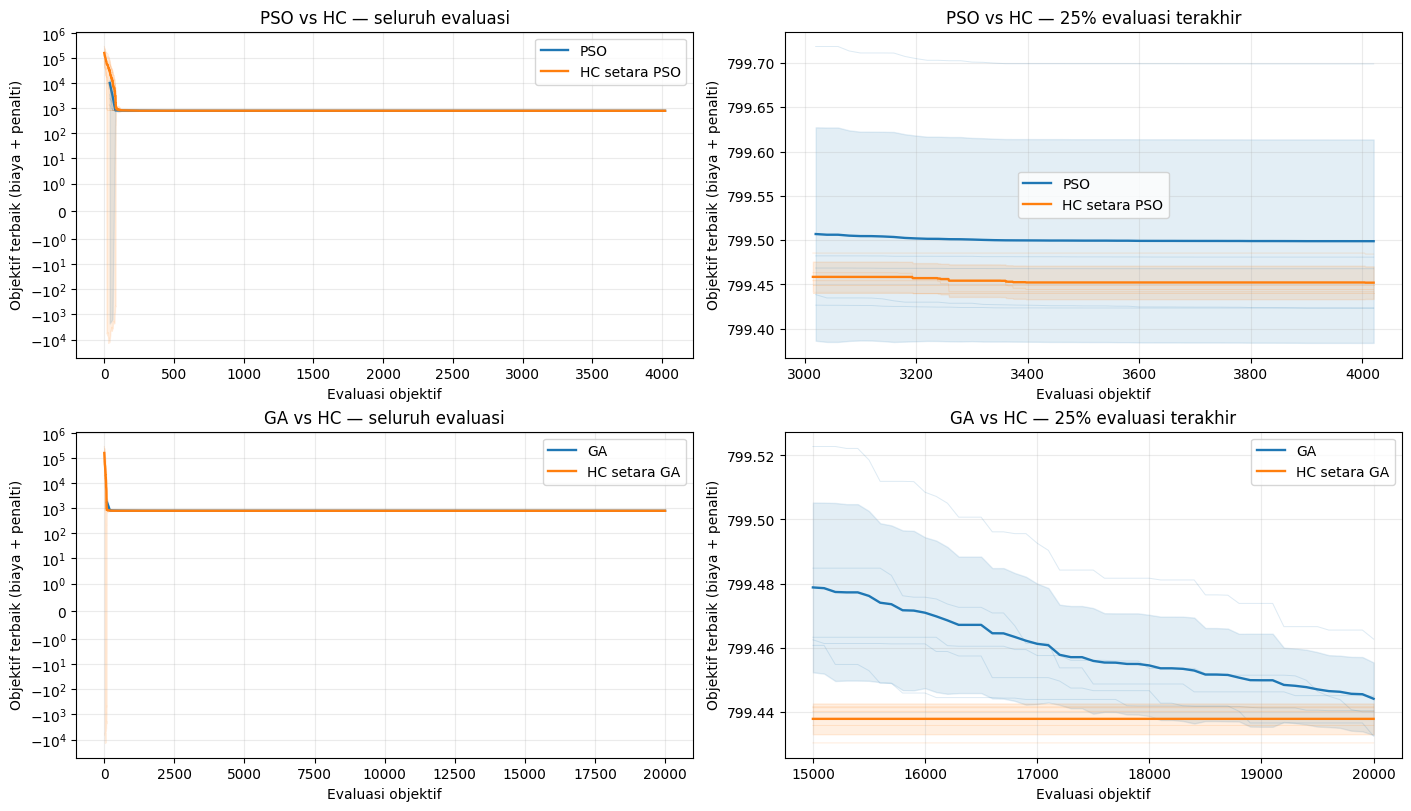

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout="constrained")
for row, pair in enumerate([("PSO", "HC setara PSO"), ("GA", "HC setara GA")]):
    for name, color in zip(pair, ["tab:blue", "tab:orange"]):
        histories = np.asarray([r["history"] for r in all_runs[name]], dtype=float)
        if name == "GA":
            xx = np.arange(1, histories.shape[1] + 1) * 100
        elif name == "PSO":
            xx = (np.arange(1, histories.shape[1] + 1) + 1) * 20
        else:
            xx = np.arange(1, histories.shape[1] + 1)
        avg, std = histories.mean(axis=0), histories.std(axis=0, ddof=1)
        for col, ax in enumerate(axes[row]):
            keep = np.ones(len(xx), dtype=bool) if col == 0 else xx >= 0.75 * BUDGETS[name]
            for yy in histories:
                ax.plot(xx[keep], yy[keep], color=color, alpha=0.15, linewidth=0.7)
            ax.plot(xx[keep], avg[keep], color=color, label=name, linewidth=1.7)
            ax.fill_between(xx[keep], (avg-std)[keep], (avg+std)[keep], color=color, alpha=0.12)
    for col, ax in enumerate(axes[row]):
        ax.set_title(f"{pair[0]} vs HC — " + ("seluruh evaluasi" if col == 0 else "25% evaluasi terakhir"))
        ax.set_xlabel("Evaluasi objektif"); ax.set_ylabel("Objektif terbaik (biaya + penalti)")
        if col == 0:
            ax.set_yscale("symlog", linthresh=1)
        ax.grid(alpha=0.25); ax.legend()
plt.show()

## Sebaran biaya tiap seed

Setiap titik mewakili satu run layak. Bentuk silang merah menandai run tidak layak bila ada; nilai biayanya tidak dipakai untuk statistik biaya layak.

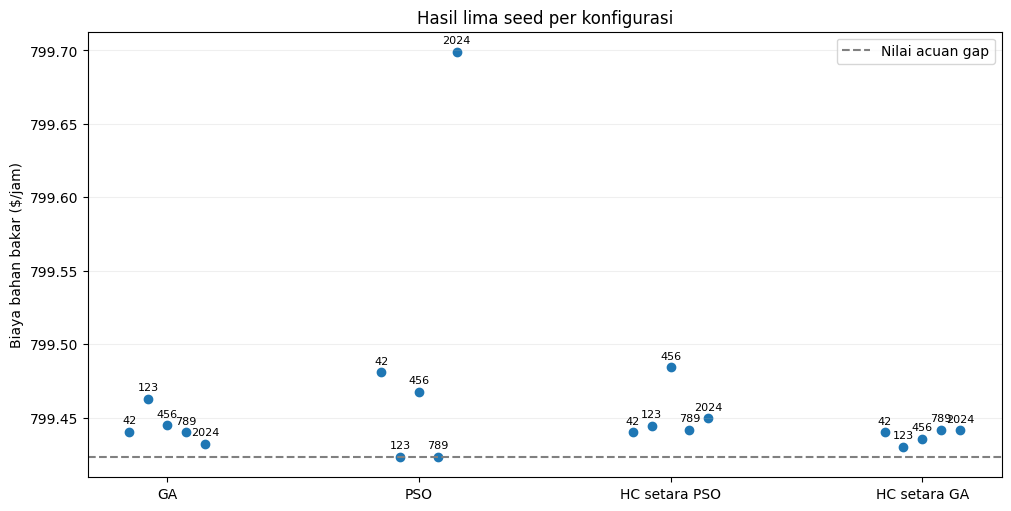

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for j, name in enumerate(METHODS):
    group = runs_df[runs_df["Metode"] == name]
    offsets = np.linspace(-0.15, 0.15, len(group))
    for offset, (_, r) in zip(offsets, group.iterrows()):
        ax.scatter(j + offset, r["Biaya ($/jam)"], marker="o" if r["Layak"] else "x",
                   color="tab:blue" if r["Layak"] else "red")
        ax.annotate(str(int(r["Seed"])), (j + offset, r["Biaya ($/jam)"]),
                    xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
if np.isfinite(reference_value):
    ax.axhline(reference_value, color="gray", linestyle="--", label="Nilai acuan gap")
ax.set_xticks(range(len(METHODS)), METHODS)
ax.set_ylabel("Biaya bahan bakar ($/jam)"); ax.set_title("Hasil lima seed per konfigurasi")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.grid(axis="y", alpha=0.2); ax.legend()
plt.show()

## Pengaturan solusi perwakilan terbaik

In [ ]:
sol = pd.DataFrame({"Batas bawah": lb, "Batas atas": ub,
                    **{name: run["x"] for name, run in results.items()}}, index=var_names)
display(sol.round(4))

,Batas bawah,Batas atas,GA,PSO,HC setara PSO,HC setara GA
P2,20.00,80.0,48.6132,48.7022,48.5003,48.7195
P5,15.00,50.0,21.2390,21.3085,21.0163,21.2920
P8,10.00,35.0,21.0590,21.0852,21.3727,21.0019
P11,10.00,30.0,12.0162,11.8570,11.9786,11.9586
P13,12.00,40.0,12.0048,12.0000,12.0000,12.0000
V1,0.95,1.1,1.1000,1.1000,1.1000,1.1000
V2,0.95,1.1,1.0863,1.0877,1.0868,1.0875
V5,0.95,1.1,1.0594,1.0612,1.0596,1.0618
V8,0.95,1.1,1.0671,1.0692,1.0675,1.0697
V11,0.95,1.1,1.1000,1.1000,1.1000,1.0999


Memeriksa pembagian daya generator.

In [ ]:
dispatch = gen[["bus", "Pmin", "Pmax", "Qmin", "Qmax"]].copy()
for name, run in results.items():
    r = run["result"]
    dispatch[f"P {name} (MW)"] = r["Pg"] if r is not None else np.nan
    dispatch[f"Q {name} (MVAr)"] = r["Qg"] if r is not None else np.nan
display(dispatch.round(3))

,bus,Pmin,Pmax,Qmin,Qmax,P GA (MW),Q GA (MVAr),P PSO (MW),Q PSO (MVAr),P HC setara PSO (MW),Q HC setara PSO (MVAr),P HC setara GA (MW),Q HC setara GA (MVAr)
0,1,50,200,-20,150.0,177.201,-13.745,177.179,-16.901,177.271,-14.235,177.161,-17.252
1,2,20,80,-20,60.0,48.613,20.017,48.702,22.875,48.500,22.766,48.719,20.451
2,5,15,50,-15,62.5,21.239,27.145,21.309,27.451,21.016,27.394,21.292,27.692
3,8,10,35,-15,48.7,21.059,36.348,21.085,38.566,21.373,39.022,21.002,37.109
4,11,10,30,-10,40.0,12.016,22.302,11.857,20.902,11.979,19.255,11.959,22.437
5,13,12,40,-15,44.7,12.005,25.016,12.000,23.556,12.000,21.771,12.000,26.354


## Cek Constraint

GA   | P gen: True | Q gen: True | Tegangan bus: True | V min=1.0349, V max=1.1000
PSO  | P gen: True | Q gen: True | Tegangan bus: True | V min=1.0367, V max=1.1000


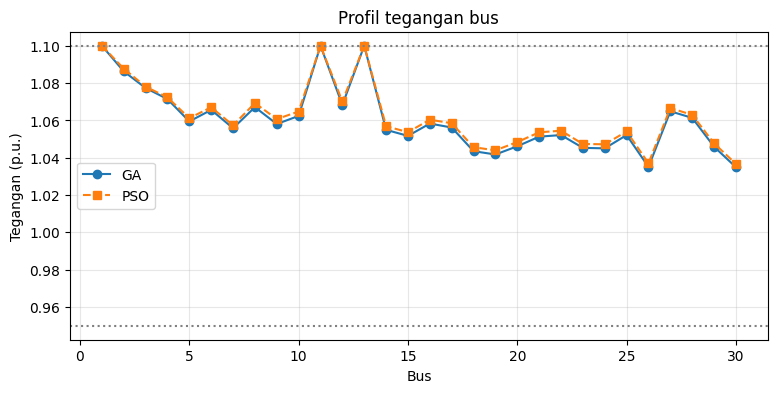

In [ ]:
def cek_batas(res, nama):
    p_ok = np.all((res["Pg"] >= gen.Pmin.values - 1e-3) & (res["Pg"] <= gen.Pmax.values + 1e-3))
    q_ok = np.all((res["Qg"] >= gen.Qmin.values - 1e-3) & (res["Qg"] <= gen.Qmax.values + 1e-3))
    v_ok = np.all((res["V"] >= V_MIN - 1e-4) & (res["V"] <= V_MAX + 1e-4))
    print(f"{nama:4s} | P gen: {p_ok} | Q gen: {q_ok} | Tegangan bus: {v_ok} "
          f"| V min={res['V'].min():.4f}, V max={res['V'].max():.4f}")

cek_batas(ga_res, "GA")
cek_batas(pso_res, "PSO")

plt.figure(figsize=(9, 4))
plt.plot(range(1, 31), ga_res["V"], "o-", label="GA")
plt.plot(range(1, 31), pso_res["V"], "s--", label="PSO")
plt.axhline(V_MIN, color="gray", ls=":"); plt.axhline(V_MAX, color="gray", ls=":")
plt.xlabel("Bus"); plt.ylabel("Tegangan (p.u.)"); plt.title("Profil tegangan bus")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Gambaran jaringan dari run terbaik

Masing-masing gambar memakai satu seed terpilih, bukan rata-rata lima solusi. Posisi bus bersifat skematis. Warna menunjukkan tegangan dengan skala yang sama; persilangan garis tanpa bus bukan sambungan.

In [ ]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

network_pos = {
    1: (0, 9), 2: (3, 9), 3: (0, 7.5), 4: (1.5, 6.5),
    5: (5.5, 9), 6: (3.5, 7), 7: (5.5, 7.5), 8: (7.5, 7),
    9: (3.7, 5.5), 10: (5, 4), 11: (2.2, 5.5), 12: (0.5, 5),
    13: (-1, 5), 14: (-0.5, 3.5), 15: (1.5, 3), 16: (2, 4.5),
    17: (3.5, 3.5), 18: (1.5, 1.5), 19: (3, 1), 20: (4, 2),
    21: (5.5, 2.5), 22: (6.5, 3.5), 23: (3, 0), 24: (6.5, 1.5),
    25: (8, 0.8), 26: (8, -0.8), 27: (9.5, 2.5), 28: (9, 6),
    29: (11, 1.5), 30: (11, -0.5),
}
assert set(network_pos) == set(bus.bus.astype(int))
voltage_norm = Normalize(vmin=V_MIN, vmax=V_MAX)
voltage_cmap = plt.get_cmap("viridis")
network_legend = [
    Line2D([], [], color="none", marker="s", markerfacecolor="white",
           markeredgecolor="#263445", markersize=9, label="Bus generator"),
    Line2D([], [], color="none", marker="o", markerfacecolor="white",
           markeredgecolor="#263445", markersize=9, label="Bus lainnya"),
    Line2D([], [], color="#7b8794", label="Saluran"),
    Line2D([], [], color="#b45309", linestyle="--", label="Cabang trafo"),
    Line2D([], [], color="none", marker="o", markeredgecolor="red",
           markersize=10, label="Tegangan di luar batas"),
]

def draw_network(ax, name, show_voltage=False):
    run = results[name]
    res = run["result"]
    if res is None:
        ax.text(0.5, 0.5, f"{name}: load flow tidak konvergen", ha="center",
                transform=ax.transAxes)
        ax.axis("off")
        return
    for k, line in branch.iterrows():
        a, b = int(line.fbus), int(line.tbus)
        xx, yy = zip(network_pos[a], network_pos[b])
        is_tap = k in tap_rows
        ax.plot(xx, yy, color="#b45309" if is_tap else "#a1aab5",
                linestyle="--" if is_tap else "-", linewidth=1.4, zorder=1)
    generators = set(gen.bus.astype(int))
    for number in bus.bus.astype(int):
        px, py = network_pos[number]
        voltage = res["V"][number - 1]
        color = voltage_cmap(voltage_norm(voltage))
        ax.scatter(px, py, s=430 if show_voltage else 330,
                   marker="s" if number in generators else "o", c=[color],
                   edgecolors="#263445", linewidths=1.2, zorder=3)
        luminance = 0.2126 * color[0] + 0.7152 * color[1] + 0.0722 * color[2]
        ax.text(px, py, str(number), color="black" if luminance > 0.55 else "white",
                ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
        if voltage < V_MIN - 1e-4 or voltage > V_MAX + 1e-4:
            ax.scatter(px, py, s=640 if show_voltage else 520, facecolors="none",
                       edgecolors="red", linewidths=2, zorder=5)
        if show_voltage:
            ax.annotate(f"{voltage:.3f}", (px, py), xytext=(0, -22),
                        textcoords="offset points", ha="center", fontsize=8,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=6)
    ax.set_title(f"{name} | seed {run['seed']} | {run['evaluations']:,} evaluasi\n"
                 f"Biaya {res['cost']:.4f} $/jam · Rugi daya {res['loss']:.3f} MW",
                 fontsize=11, pad=15)
    ax.set_xlim(-1.8, 11.8); ax.set_ylim(-1.7, 9.9)
    ax.set_aspect("equal"); ax.axis("off")

Menyiapkan panel diagram dan pengaturan tiap solusi.

In [ ]:
def draw_network_detail(metode_network):
    selected = results[metode_network]
    fig_detail = plt.figure(figsize=(16, 10), layout="constrained")
    grid = fig_detail.add_gridspec(1, 2, width_ratios=[3, 1.1])
    ax_map = fig_detail.add_subplot(grid[0, 0])
    ax_info = fig_detail.add_subplot(grid[0, 1]); ax_info.axis("off")
    draw_network(ax_map, metode_network, show_voltage=True)
    if selected["result"] is not None:
        rr, xx = selected["result"], selected["x"]
        detail_rows = [[f"Generator bus {int(b)}", f"{p:.2f} MW"]
                       for b, p in zip(gen.bus, rr["Pg"])]
        detail_rows += [[var_names[11 + j], f"{xx[11 + j]:.4f}"] for j in range(4)]
        detail_rows += [[f"Qc bus {b}", f"{xx[15 + j]:.3f} MVAr"]
                        for j, b in enumerate(shunt_bus)]
        tab = ax_info.table(cellText=detail_rows, colLabels=["Pengaturan", "Nilai"],
                            cellLoc="left", colLoc="left", bbox=[0, 0.23, 1, 0.65])
        tab.auto_set_font_size(False); tab.set_fontsize(10)
        for (row, col), cell in tab.get_celld().items():
            cell.set_edgecolor("#e0e5eb")
            if row == 0:
                cell.set_facecolor("#23364d"); cell.set_text_props(color="white", weight="bold")
            else:
                cell.set_facecolor("#f1f5f9" if row % 2 else "white")
        ax_info.text(0, 0.94, "Pengaturan hasil optimasi", weight="bold", fontsize=13,
                     transform=ax_info.transAxes)
        ax_info.text(0, 0.13, f"Total pembangkitan: {rr['Pg'].sum():.2f} MW\n"
                     f"Total beban: {bus.Pd.sum():.2f} MW\n"
                     f"Rugi daya: {rr['loss']:.2f} MW", fontsize=11,
                     transform=ax_info.transAxes, linespacing=1.6)
    fig_detail.colorbar(ScalarMappable(norm=voltage_norm, cmap=voltage_cmap),
                       ax=ax_map, shrink=0.6, label="Tegangan bus (p.u.)", pad=0.01)
    ax_map.legend(handles=network_legend, loc="upper left", bbox_to_anchor=(0, -0.02),
                  ncol=3, fontsize=8, frameon=False)
    plt.show()
    return fig_detail

network_details = {}

Menampilkan jaringan GA dari seed terpilih.

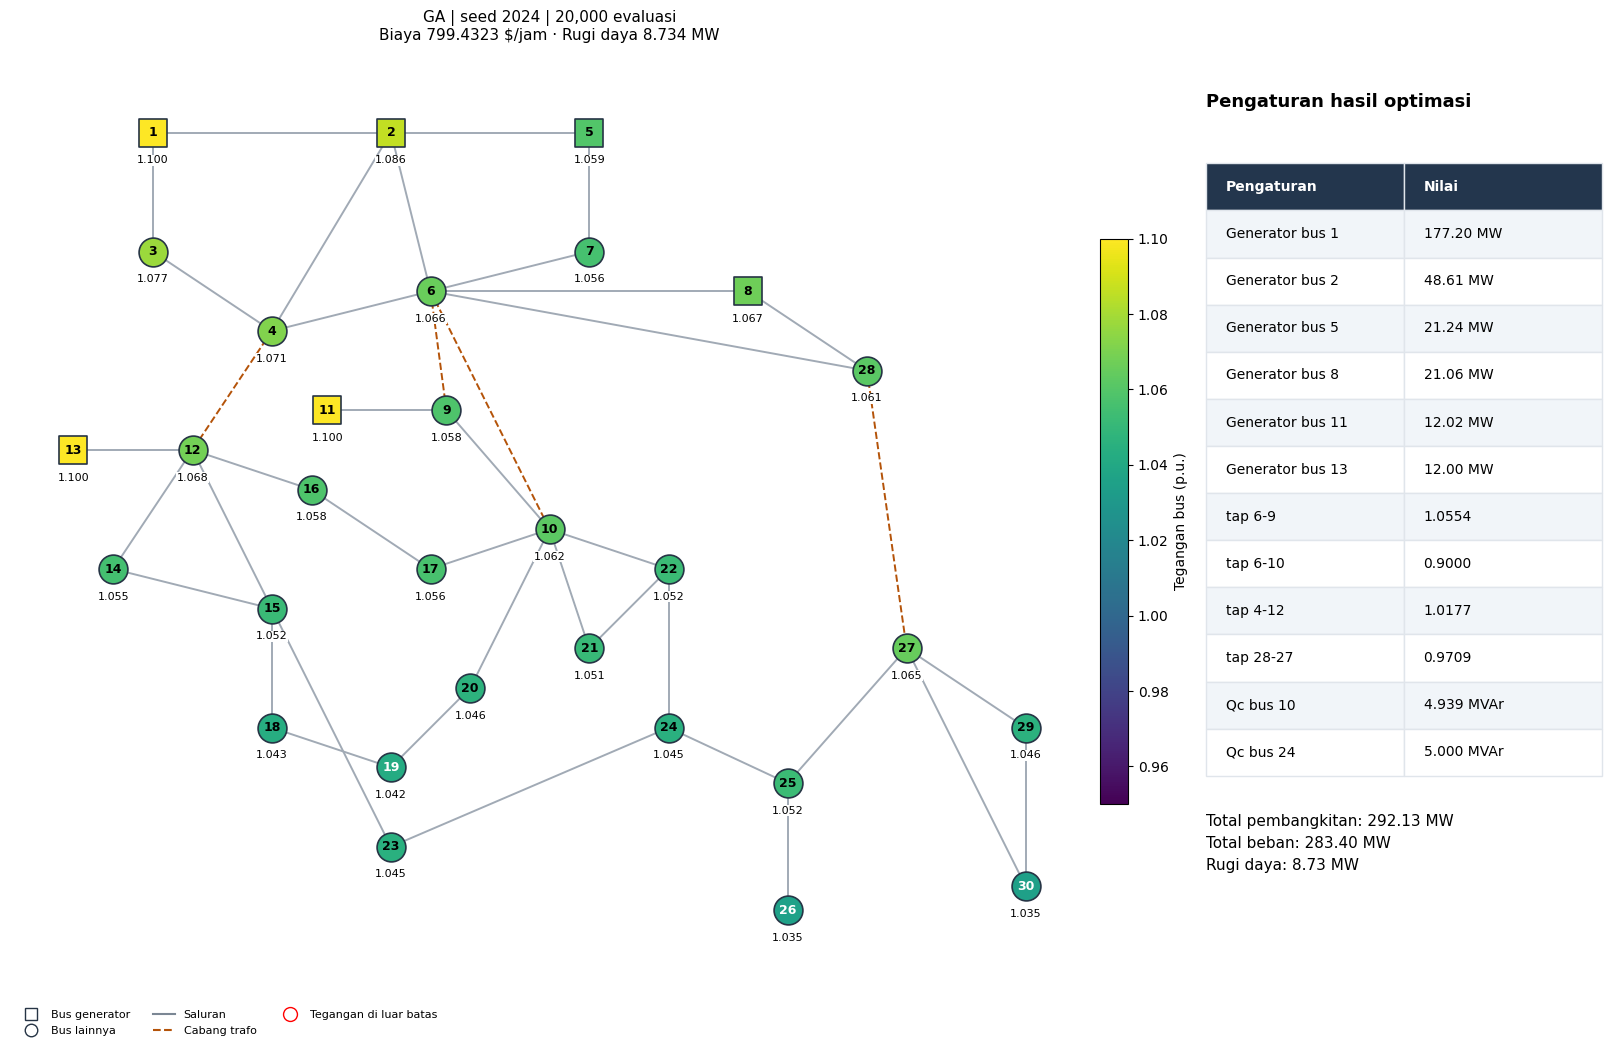

In [ ]:
network_details["GA"] = draw_network_detail("GA")

Menampilkan jaringan PSO dari seed terpilih.

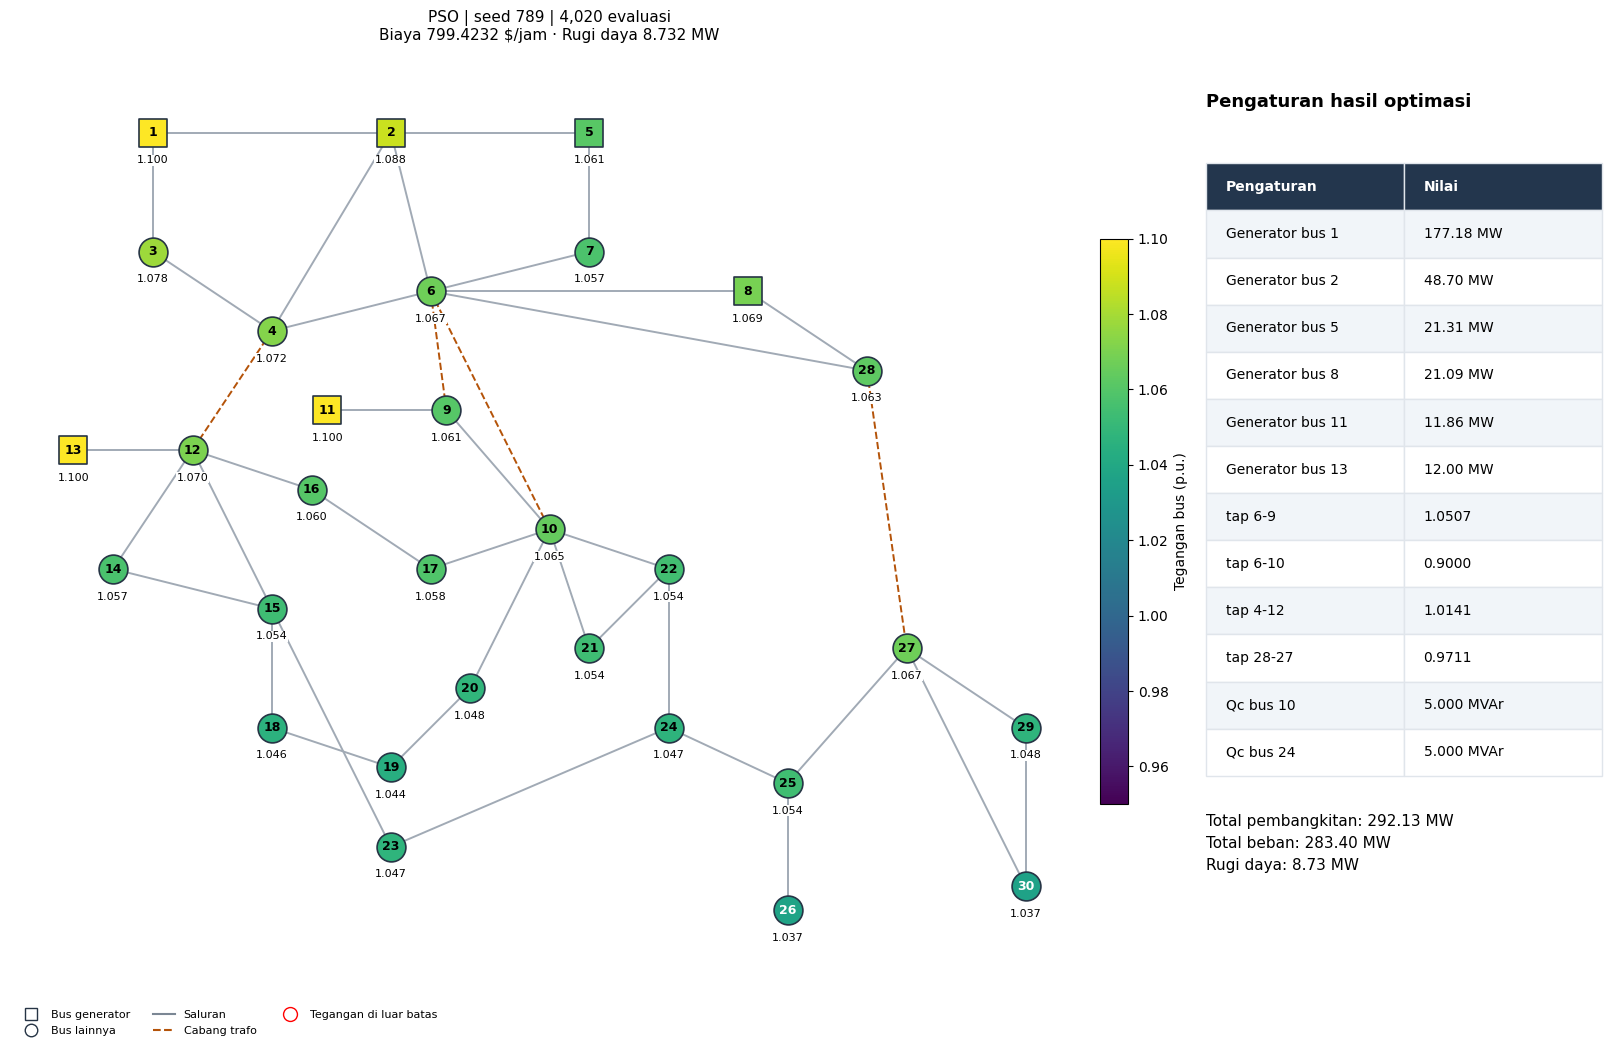

In [ ]:
network_details["PSO"] = draw_network_detail("PSO")

Menampilkan jaringan HC setara PSO dari seed terpilih.

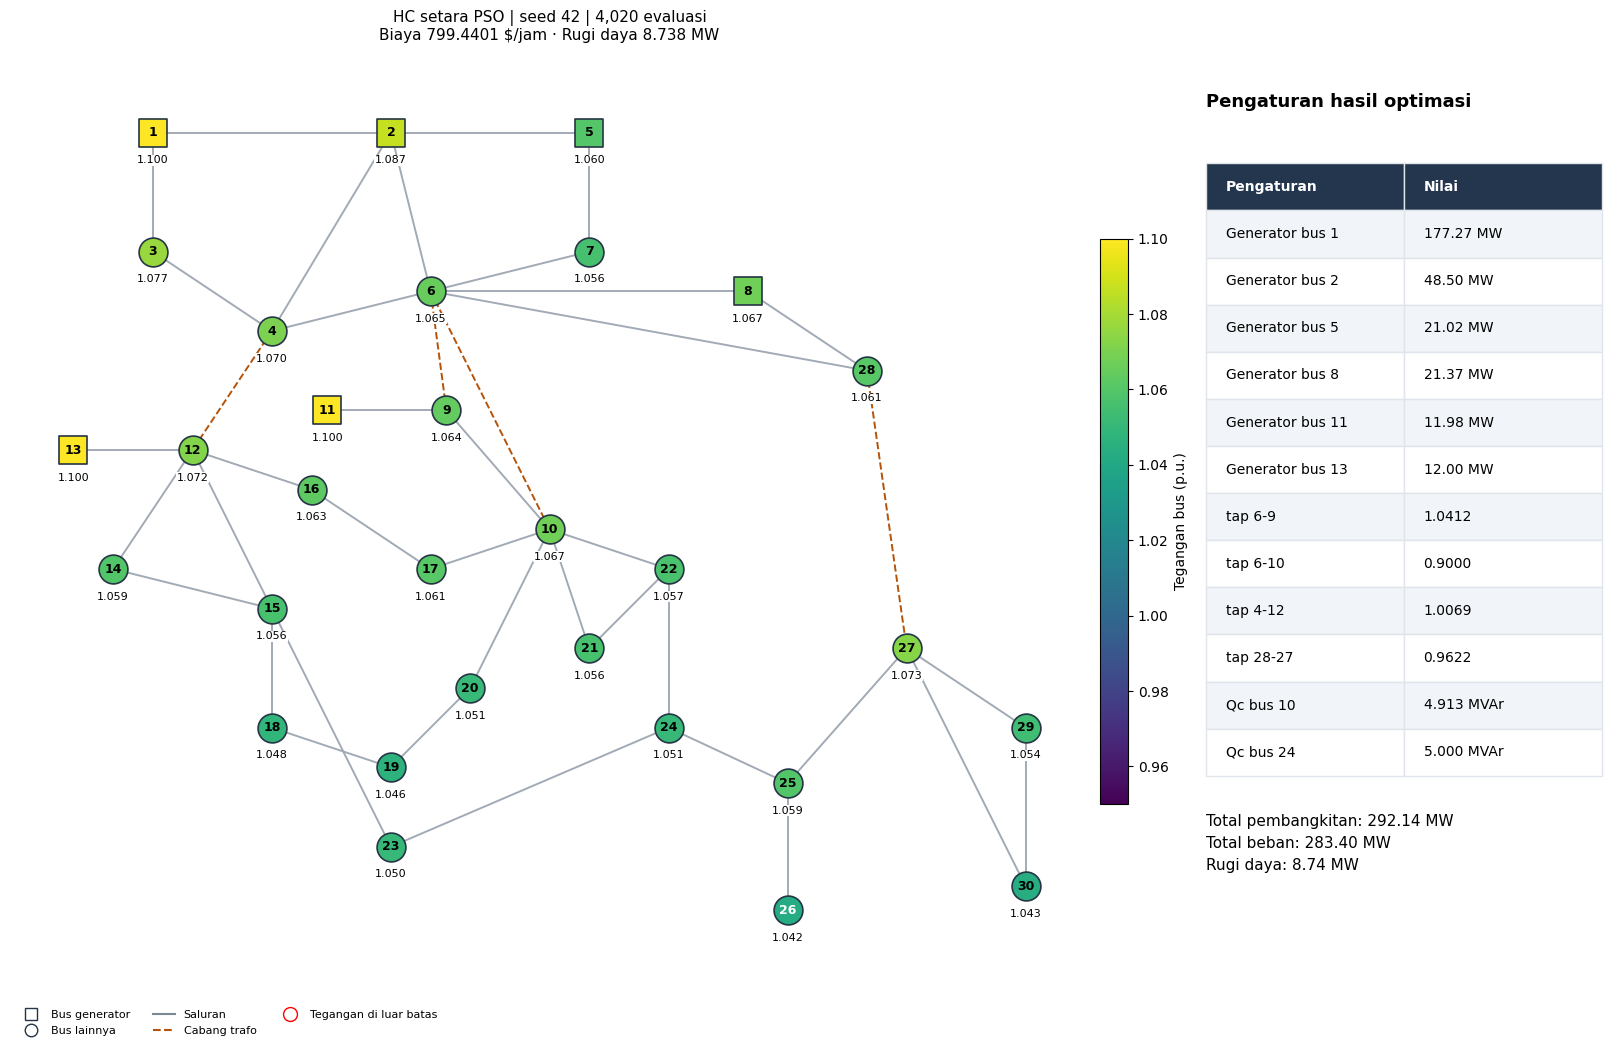

In [ ]:
network_details["HC setara PSO"] = draw_network_detail("HC setara PSO")

Menampilkan jaringan HC setara GA dari seed terpilih.

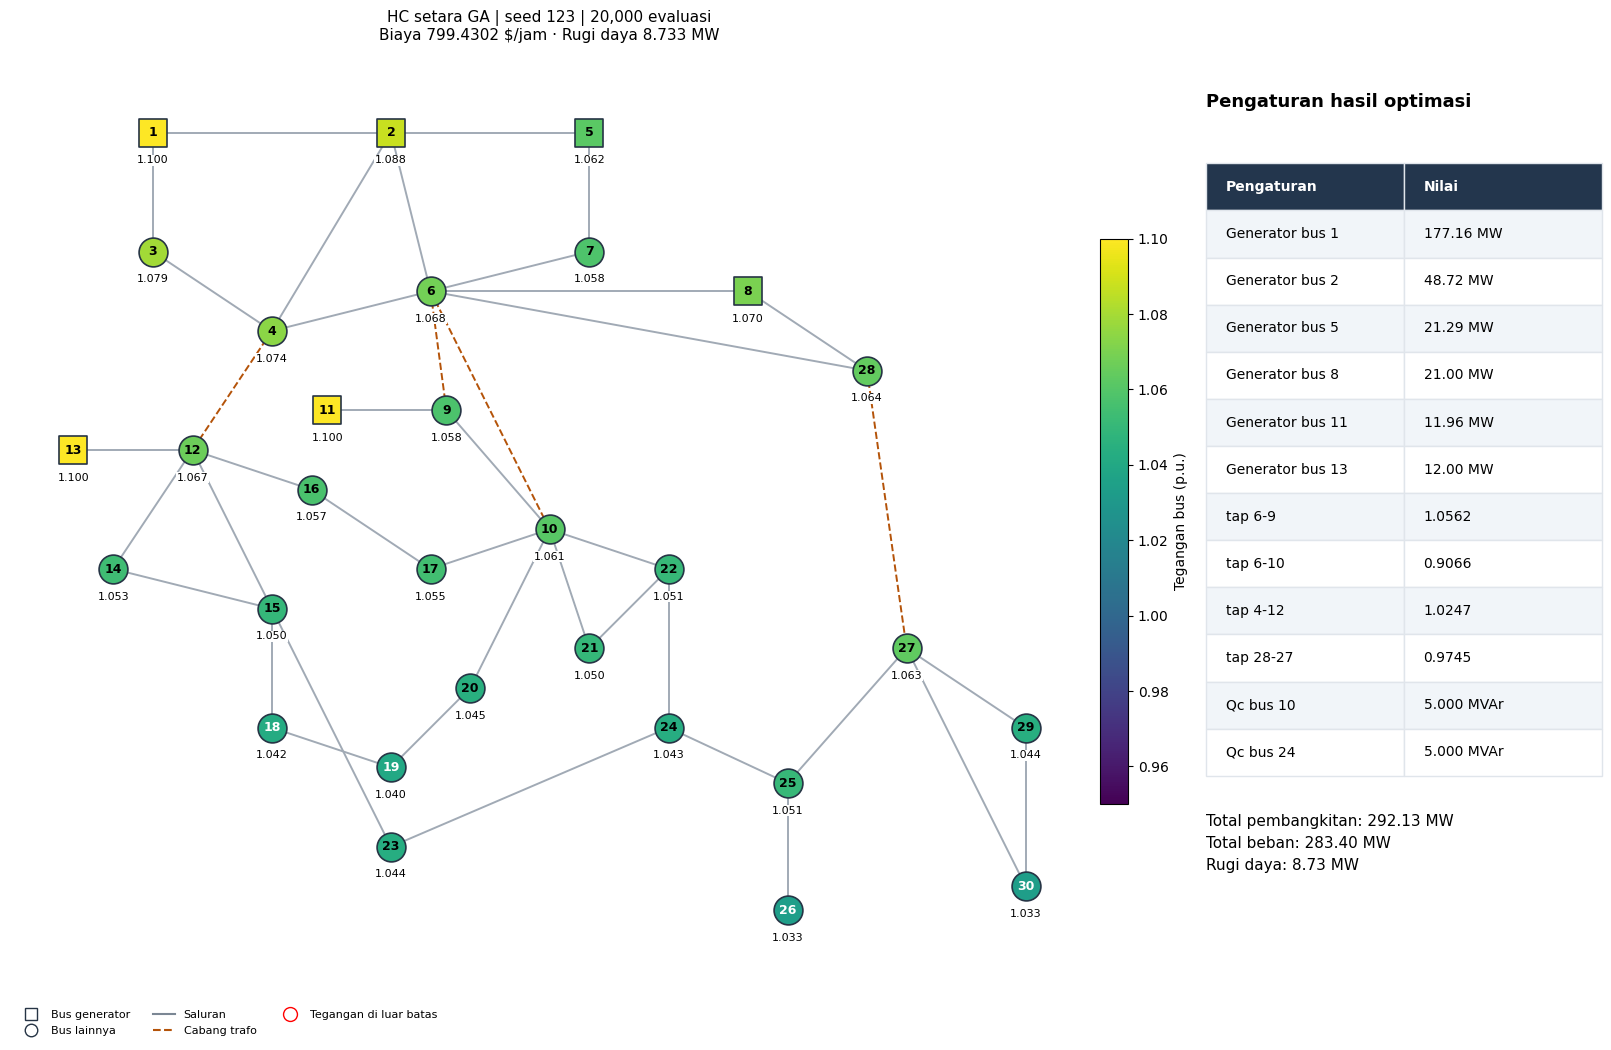

In [ ]:
network_details["HC setara GA"] = draw_network_detail("HC setara GA")

## Ringkasan hasil lima seed

Rata-rata dan simpangan baku menjelaskan performa antar-run; satu run terbaik saja tidak cukup untuk menilai kestabilan. Gap terhadap best-known empiris hanya menunjukkan jarak dari hasil terbaik dalam eksperimen ini. Untuk klaim terhadap optimum atau best-known literatur, masukkan nilai dan sumber yang sesuai pada konfigurasi lalu jalankan ulang analisis.

In [ ]:
for name in METHODS:
    row = cost_summary.loc[(INSTANCE, name)]
    print(f"{name}: layak {row['Run layak / total']}; "
          f"terbaik={row['Terbaik ($/jam)']:.6f}; rata-rata={row['Rata-rata ($/jam)']:.6f}; "
          f"SD={row['Simpangan baku ($/jam)']:.6f}; terburuk={row['Terburuk ($/jam)']:.6f}; "
          f"gap rata-rata={row['Gap rata-rata (%)']:.6f}%")
print(f"Acuan gap: {reference_value:.8f} $/jam — {reference_label}")

GA: layak 5/5; terbaik=799.432346; rata-rata=799.444015; SD=0.011340; terburuk=799.462653; gap rata-rata=0.002609%
PSO: layak 5/5; terbaik=799.423159; rata-rata=799.498757; SD=0.114901; terburuk=799.698998; gap rata-rata=0.009457%
HC setara PSO: layak 5/5; terbaik=799.440075; rata-rata=799.451912; SD=0.018414; terburuk=799.484204; gap rata-rata=0.003597%
HC setara GA: layak 5/5; terbaik=799.430241; rata-rata=799.437748; SD=0.004802; terburuk=799.441513; gap rata-rata=0.001825%
Acuan gap: 799.42315929 $/jam — Best-known empiris dari seluruh run eksperimen ini (bukan optimum global)
